In [1]:
import os
import warnings
import pandas as pd

# Mot so phien ban scikit-learn bao FutureWarning cho SVC(probability=True) o muc 6
warnings.filterwarnings("ignore", category=FutureWarning)


def doc_csv(ten_tep):
    """Doc tep csv trong thu muc data/, neu khong co thi doc o thu muc hien tai."""
    duong_dan = os.path.join("data", ten_tep)
    if not os.path.exists(duong_dan):
        duong_dan = ten_tep
    return pd.read_csv(duong_dan)

## 2. Khi accuracy đánh lừa

In [2]:
# -*- coding: utf-8 -*-
"""Bước 1: thấy accuracy đánh lừa trên dữ liệu lệch lớp.

Chú thích viết tiếng Việt có dấu, phần in ra màn hình viết không dấu.
"""

import pandas as pd
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

df = doc_csv("sinh_vien_bo_hoc.csv")
print("Kich thuoc bang:", df.shape)
print(df.head())
print()
print("So sinh vien moi lop:")
print(df["bo_hoc"].value_counts().to_string())
print(f"Ty le bo hoc: {df['bo_hoc'].mean():.3f}")
print()

X = df.drop(columns="bo_hoc")
y = df["bo_hoc"]
# stratify=y giữ đúng tỷ lệ bỏ học ở cả tập học lẫn tập kiểm tra
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)
print(f"Tap kiem tra: {len(y_te)} ban, {y_te.sum()} ban bo hoc")
print()

# Mô hình lười: ai cũng đoán là lớp đông nhất
luoi = DummyClassifier(strategy="most_frequent").fit(X_tr, y_tr)
du_luoi = luoi.predict(X_te)

lr = make_pipeline(StandardScaler(), LogisticRegression())
lr.fit(X_tr, y_tr)
du_lr = lr.predict(X_te)

for ten, du in [("Mo hinh luoi", du_luoi), ("Hoi quy logistic", du_lr)]:
    acc = accuracy_score(y_te, du)
    tim_ra = ((du == 1) & (y_te == 1)).sum()
    print(f"{ten:17s} accuracy {acc:.4f}, "
            f"tim ra {tim_ra} tren {y_te.sum()} ban bo hoc")

Kich thuoc bang: (1200, 5)
   diem_tb  so_buoi_vang  tin_chi_no  gio_lam_them  bo_hoc
0      8.0             3           0             0       0
1      8.9             5           1             7       0
2      3.3             3           1             4       0
3      6.4             3           0             7       0
4      7.9             3           5            23       0

So sinh vien moi lop:
bo_hoc
0    1081
1     119
Ty le bo hoc: 0.099

Tap kiem tra: 300 ban, 30 ban bo hoc

Mo hinh luoi      accuracy 0.9000, tim ra 0 tren 30 ban bo hoc
Hoi quy logistic  accuracy 0.9467, tim ra 17 tren 30 ban bo hoc


## 3. Ma trận nhầm lẫn

In [3]:
# -*- coding: utf-8 -*-
"""Bước 2: tự đếm bốn ô của ma trận nhầm lẫn, rồi so với thư viện."""

import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

df = doc_csv("sinh_vien_bo_hoc.csv")
X = df.drop(columns="bo_hoc")
y = df["bo_hoc"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

lr = make_pipeline(StandardScaler(), LogisticRegression())
du = lr.fit(X_tr, y_tr).predict(X_te)
that = y_te.to_numpy()

# Tự đếm: mỗi ô là một cặp (nhãn thật, nhãn đoán)
tp = np.sum((that == 1) & (du == 1))
fp = np.sum((that == 0) & (du == 1))
fn = np.sum((that == 1) & (du == 0))
tn = np.sum((that == 0) & (du == 0))
print("Tu dem:")
print(f" TP = {tp} (doan bo hoc, dung la bo hoc)")
print(f" FP = {fp} (bao dong nham)")
print(f" FN = {fn} (bo sot)")
print(f" TN = {tn} (doan khong bo, dung la khong bo)")
print(f" Tong = {tp + fp + fn + tn}")
print()

m = confusion_matrix(that, du)
print("confusion_matrix cua scikit-learn:")
print(m)
print("Thu tu khi trai ra: TN, FP, FN, TP =", m.ravel())
print()

acc = (tp + tn) / (tp + fp + fn + tn)
print(f"Accuracy tinh tu bon o: ({tp} + {tn}) / {len(that)} = {acc:.4f}")
print(f"So ban bi bao co nguy co: TP + FP = {tp + fp}")

Tu dem:
 TP = 17 (doan bo hoc, dung la bo hoc)
 FP = 3 (bao dong nham)
 FN = 13 (bo sot)
 TN = 267 (doan khong bo, dung la khong bo)
 Tong = 300

confusion_matrix cua scikit-learn:
[[267   3]
 [ 13  17]]
Thu tu khi trai ra: TN, FP, FN, TP = [267   3  13  17]

Accuracy tinh tu bon o: (17 + 267) / 300 = 0.9467
So ban bi bao co nguy co: TP + FP = 20


## 4. Precision, recall và F1

In [4]:
# -*- coding: utf-8 -*-
"""Bước 3: precision, recall, F1 tính tay và tính bằng thư viện."""

import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (classification_report, confusion_matrix,
                            f1_score, precision_score, recall_score)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

df = doc_csv("sinh_vien_bo_hoc.csv")
X = df.drop(columns="bo_hoc")
y = df["bo_hoc"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

lr = make_pipeline(StandardScaler(), LogisticRegression())
du = lr.fit(X_tr, y_tr).predict(X_te)
tn, fp, fn, tp = confusion_matrix(y_te, du).ravel()

p = tp / (tp + fp)
r = tp / (tp + fn)
f1 = 2 * p * r / (p + r)
print("Tinh tay tu bon o:")
print(f" Precision = {tp} / ({tp} + {fp}) = {p:.4f}")
print(f" Recall     = {tp} / ({tp} + {fn}) = {r:.4f}")
print(f" F1         = 2 x {p:.4f} x {r:.4f} / ({p:.4f} + {r:.4f})"
        f" = {f1:.4f}")
print()

print("Tinh bang scikit-learn:")
print(f" Precision = {precision_score(y_te, du):.4f}")
print(f" Recall     = {recall_score(y_te, du):.4f}")
print(f" F1         = {f1_score(y_te, du):.4f}")
print()

print("Bao cao day du:")
print(classification_report(y_te, du, digits=4,
                            target_names=["khong bo", "bo hoc"]))

Tinh tay tu bon o:
 Precision = 17 / (17 + 3) = 0.8500
 Recall     = 17 / (17 + 13) = 0.5667
 F1         = 2 x 0.8500 x 0.5667 / (0.8500 + 0.5667) = 0.6800

Tinh bang scikit-learn:
 Precision = 0.8500
 Recall     = 0.5667
 F1         = 0.6800

Bao cao day du:
              precision    recall  f1-score   support

    khong bo     0.9536    0.9889    0.9709       270
      bo hoc     0.8500    0.5667    0.6800        30

    accuracy                         0.9467       300
   macro avg     0.9018    0.7778    0.8255       300
weighted avg     0.9432    0.9467    0.9418       300



## 5. Đổi ngưỡng quyết định

In [5]:
# -*- coding: utf-8 -*-
"""Bước 4: đổi ngưỡng, và chọn ngưỡng đúng cách trên tập học."""

import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, precision_score, recall_score
from sklearn.model_selection import cross_val_predict, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

df = doc_csv("sinh_vien_bo_hoc.csv")
X = df.drop(columns="bo_hoc")
y = df["bo_hoc"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

lr = make_pipeline(StandardScaler(), LogisticRegression())
lr.fit(X_tr, y_tr)
xs = lr.predict_proba(X_te)[:, 1]      # xác suất bỏ học của từng bạn

print("Tap kiem tra, doi nguong")
print("nguong so bao    TP FP FN     precision recall     F1")
for t in [0.5, 0.4, 0.3, 0.2, 0.1]:
    du = (xs >= t).astype(int)
    tp = int(((du == 1) & (y_te == 1)).sum())
    fp = int(((du == 1) & (y_te == 0)).sum())
    fn = int(((du == 0) & (y_te == 1)).sum())
    print(f" {t:.1f}     {du.sum():4d}   {tp:3d} {fp:3d} {fn:3d}"
        f"    {precision_score(y_te, du):.4f}   "
        f"{recall_score(y_te, du):.4f} {f1_score(y_te, du):.4f}")
print()

# Chọn ngưỡng đúng cách: chỉ dùng tập học, qua kiểm định chéo.
# Mỗi bạn trong tập học nhận xác suất từ một mô hình chưa từng thấy bạn ấy.
xs_hoc = cross_val_predict(lr, X_tr, y_tr, cv=5,
                            method="predict_proba")[:, 1]
cac_nguong = np.round(np.arange(0.05, 0.96, 0.05), 2)
f1_hoc = [f1_score(y_tr, (xs_hoc >= t).astype(int)) for t in cac_nguong]
t_tot = cac_nguong[int(np.argmax(f1_hoc))]
print(f"Nguong cho F1 cao nhat tren tap hoc: {t_tot}"
        f" (F1 kiem dinh cheo {max(f1_hoc):.4f})")

# Chọn xong mới dùng tập kiểm tra, và chỉ một lần
du = (xs >= t_tot).astype(int)
print(f"Tap kiem tra voi nguong {t_tot}:"
        f" precision {precision_score(y_te, du):.4f},"
        f" recall {recall_score(y_te, du):.4f},"
        f" F1 {f1_score(y_te, du):.4f}")

Tap kiem tra, doi nguong
nguong so bao    TP FP FN     precision recall     F1
 0.5       20    17   3  13    0.8500   0.5667 0.6800
 0.4       21    18   3  12    0.8571   0.6000 0.7059
 0.3       29    21   8   9    0.7241   0.7000 0.7119
 0.2       42    24  18   6    0.5714   0.8000 0.6667
 0.1       61    26  35   4    0.4262   0.8667 0.5714



Nguong cho F1 cao nhat tren tap hoc: 0.25 (F1 kiem dinh cheo 0.6473)
Tap kiem tra voi nguong 0.25: precision 0.6571, recall 0.7667, F1 0.7077


## 6. Đường ROC và AUC

In [6]:
# -*- coding: utf-8 -*-
"""Bước 5: đường ROC, AUC, và so các mô hình đã học trong môn."""

import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, recall_score, roc_auc_score
from sklearn.metrics import roc_curve
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

df = doc_csv("sinh_vien_bo_hoc.csv")
X = df.drop(columns="bo_hoc")
y = df["bo_hoc"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

lr = make_pipeline(StandardScaler(), LogisticRegression())
xs = lr.fit(X_tr, y_tr).predict_proba(X_te)[:, 1]

# Mỗi ngưỡng cho một điểm của đường ROC
fpr, tpr, nguong = roc_curve(y_te, xs)
print("Duong ROC co", len(fpr), "diem. Vai diem dau:")
print(" bao dong nham     recall")
for a, b in list(zip(fpr, tpr))[:6]:
    print(f"      {a:.4f}       {b:.4f}")
print(f"AUC cua logistic = {roc_auc_score(y_te, xs):.4f}")
print()

# So các mô hình đã học, cùng tập học, cùng tập kiểm tra
mo_hinh = {
    "Logistic": lr,
    "Naive Bayes": GaussianNB(),
    "KNN, k = 15": make_pipeline(StandardScaler(),
                                KNeighborsClassifier(15)),
    "Cay sau 4": DecisionTreeClassifier(max_depth=4, random_state=0),
    "Rung 200 cay": RandomForestClassifier(200, random_state=0),
    "SVM RBF": make_pipeline(StandardScaler(),
                            SVC(probability=True, random_state=0)),
}
print("Mo hinh          AUC      recall    F1   (nguong 0.5)")
for ten, mh in mo_hinh.items():
    mh.fit(X_tr, y_tr)
    p = mh.predict_proba(X_te)[:, 1]
    du = (p >= 0.5).astype(int)
    print(f" {ten:14s} {roc_auc_score(y_te, p):.4f}    "
        f"{recall_score(y_te, du):.4f} {f1_score(y_te, du):.4f}")

Duong ROC co 28 diem. Vai diem dau:
 bao dong nham     recall
      0.0000       0.0000
      0.0000       0.0333
      0.0000       0.4000
      0.0074       0.4000
      0.0074       0.5333
      0.0111       0.5333
AUC cua logistic = 0.9449

Mo hinh          AUC      recall    F1   (nguong 0.5)
 Logistic       0.9449    0.5667 0.6800


 Naive Bayes    0.9336    0.3667 0.5116
 KNN, k = 15    0.9274    0.2333 0.3684
 Cay sau 4      0.8803    0.4667 0.5957


 Rung 200 cay   0.9249    0.5667 0.6538
 SVM RBF        0.8996    0.5000 0.6250


## 7. Kiểm định chéo nhiều thước đo và cân bằng lớp

In [7]:
# -*- coding: utf-8 -*-
"""Bước 6: kiểm định chéo với nhiều thước đo, và cân bằng lớp khi học."""

import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, precision_score, recall_score
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

df = doc_csv("sinh_vien_bo_hoc.csv")
X = df.drop(columns="bo_hoc")
y = df["bo_hoc"]

# Chia không phân tầng: số bạn bỏ học trong tập kiểm tra dao động
print("Khong stratify, so ban bo hoc trong tap kiem tra:")
dem = []
for rs in range(10):
    _, _, _, y_te_thu = train_test_split(X, y, test_size=0.25,
                                        random_state=rs)
    dem.append(int(y_te_thu.sum()))
print(" ", dem)
print()

X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

lr = make_pipeline(StandardScaler(), LogisticRegression())
print("Kiem dinh cheo 5 phan tren tap hoc:")
for tm in ["accuracy", "precision", "recall", "f1"]:
    d = cross_val_score(lr, X_tr, y_tr, cv=5, scoring=tm)
    print(f" {tm:10s} {d.mean():.4f}")
print()

# Cân bằng lớp: phạt nặng hơn khi đoán sai lớp hiếm
cb = make_pipeline(StandardScaler(),
                    LogisticRegression(class_weight="balanced"))
print("Tap kiem tra   precision recall     F1")
for ten, mh in [("Binh thuong", lr), ("Can bang lop", cb)]:
    du = mh.fit(X_tr, y_tr).predict(X_te)
    print(f" {ten:12s} {precision_score(y_te, du):.4f}"
          f"    {recall_score(y_te, du):.4f} {f1_score(y_te, du):.4f}")

Khong stratify, so ban bo hoc trong tap kiem tra:
  [22, 26, 35, 29, 32, 27, 28, 20, 27, 23]

Kiem dinh cheo 5 phan tren tap hoc:
 accuracy   0.9289
 precision  0.7044
 recall     0.4810


 f1         0.5652

Tap kiem tra   precision recall     F1


 Binh thuong  0.8500    0.5667 0.6800
 Can bang lop 0.4483    0.8667 0.5909


# 8. Bài tập

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_digits
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (accuracy_score, classification_report, f1_score,
                             mean_absolute_error, mean_squared_error,
                             precision_score, r2_score, recall_score,
                             roc_auc_score, roc_curve)
from sklearn.model_selection import cross_val_predict, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

# Du lieu sinh vien bo hoc, chia 75/25 co phan tang, giong het tai lieu
df = doc_csv("sinh_vien_bo_hoc.csv")
X = df.drop(columns="bo_hoc")
y = df["bo_hoc"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

# Hai mo hinh cua muc 2: mo hinh luoi va hoi quy logistic
mo_hinh_luoi = DummyClassifier(strategy="most_frequent").fit(X_tr, y_tr)
du_doan_luoi = mo_hinh_luoi.predict(X_te)
logistic = make_pipeline(StandardScaler(), LogisticRegression()).fit(X_tr, y_tr)
du_doan_logistic = logistic.predict(X_te)
xac_suat_kt = logistic.predict_proba(X_te)[:, 1]
print(f"Tap hoc {len(y_tr)} ban ({y_tr.sum()} bo hoc), "
      f"tap kiem tra {len(y_te)} ban ({y_te.sum()} bo hoc)")

Tap hoc 900 ban (89 bo hoc), tap kiem tra 300 ban (30 bo hoc)


## Bài tập 1: Tự viết hàm đánh giá

In [9]:
def danh_gia(y_that, y_doan):
    """Tra ve accuracy, precision, recall, F1, chi dung numpy.

    Neu mau so bang 0 thi thuoc do do khong xac dinh, ham tra ve nan.
    """
    y_that = np.asarray(y_that)
    y_doan = np.asarray(y_doan)
    tp = np.sum((y_doan == 1) & (y_that == 1))
    fp = np.sum((y_doan == 1) & (y_that == 0))
    fn = np.sum((y_doan == 0) & (y_that == 1))
    tn = np.sum((y_doan == 0) & (y_that == 0))

    accuracy = (tp + tn) / (tp + tn + fp + fn)
    precision = tp / (tp + fp) if (tp + fp) > 0 else np.nan
    recall = tp / (tp + fn) if (tp + fn) > 0 else np.nan
    # F1 viet theo bon o: 2TP / (2TP + FP + FN), van tinh duoc khi TP = 0
    f1 = 2 * tp / (2 * tp + fp + fn) if (2 * tp + fp + fn) > 0 else np.nan
    return accuracy, precision, recall, f1, (tp, fp, fn, tn)


for ten, du_doan in [("Hoi quy logistic", du_doan_logistic),
                     ("Mo hinh luoi", du_doan_luoi)]:
    acc, pre, rec, f1, (tp, fp, fn, tn) = danh_gia(y_te, du_doan)
    print(f"{ten}: TP = {tp}, FP = {fp}, FN = {fn}, TN = {tn}")
    print(f"  tu viet     : accuracy {acc:.4f}  precision {pre:.4f}  "
          f"recall {rec:.4f}  F1 {f1:.4f}")
    print(f"  scikit-learn: accuracy {accuracy_score(y_te, du_doan):.4f}  "
          f"precision {precision_score(y_te, du_doan, zero_division=0):.4f}  "
          f"recall {recall_score(y_te, du_doan):.4f}  "
          f"F1 {f1_score(y_te, du_doan):.4f}")
    print()

Hoi quy logistic: TP = 17, FP = 3, FN = 13, TN = 267
  tu viet     : accuracy 0.9467  precision 0.8500  recall 0.5667  F1 0.6800
  scikit-learn: accuracy 0.9467  precision 0.8500  recall 0.5667  F1 0.6800

Mo hinh luoi: TP = 0, FP = 0, FN = 30, TN = 270
  tu viet     : accuracy 0.9000  precision nan  recall 0.0000  F1 0.0000
  scikit-learn: accuracy 0.9000  precision 0.0000  recall 0.0000  F1 0.0000



**Nhận xét:** Với hồi quy logistic, hàm tự viết đếm được TP = 17, FP = 3, FN = 13, TN = 267 và cho accuracy 0.9467, precision 0.8500, recall 0.5667, F1 0.6800, trùng khớp với scikit-learn. Mỗi thước đo chỉ là một phép chia trên bốn ô: accuracy = (TP + TN) / tất cả, precision = TP / (TP + FP) là trong số bạn bị báo có bao nhiêu bạn bỏ học thật, recall = TP / (TP + FN) là trong số bạn bỏ học thật tìm ra được bao nhiêu.

## Bài tập 2: Chữ số viết tay

In [10]:
X_chu, y_chu = load_digits(return_X_y=True)
Xc_tr, Xc_te, yc_tr, yc_te = train_test_split(
    X_chu, y_chu, test_size=0.25, random_state=17, stratify=y_chu
)
svm_chu = SVC(kernel="rbf").fit(Xc_tr, yc_tr)
du_doan_chu = svm_chu.predict(Xc_te)
print(classification_report(yc_te, du_doan_chu, digits=4))

bao_cao = classification_report(yc_te, du_doan_chu, output_dict=True)
bang_chu = pd.DataFrame({so: bao_cao[str(so)] for so in range(10)}).T
print("Chu so co recall thap nhat   :", bang_chu["recall"].idxmin(),
      f"({bang_chu['recall'].min():.4f})")
print("Chu so co precision thap nhat:",
      list(bang_chu.index[bang_chu["precision"] == bang_chu["precision"].min()]),
      f"({bang_chu['precision'].min():.4f})")
print("So anh moi chu so trong tap kiem tra:", np.bincount(yc_te))

              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000        45
           1     0.9787    1.0000    0.9892        46
           2     1.0000    1.0000    1.0000        44
           3     0.9787    1.0000    0.9892        46
           4     1.0000    0.9778    0.9888        45
           5     1.0000    1.0000    1.0000        46
           6     1.0000    1.0000    1.0000        45
           7     1.0000    0.9778    0.9888        45
           8     0.9767    0.9767    0.9767        43
           9     0.9778    0.9778    0.9778        45

    accuracy                         0.9911       450
   macro avg     0.9912    0.9910    0.9911       450
weighted avg     0.9912    0.9911    0.9911       450

Chu so co recall thap nhat   : 8 (0.9767)
Chu so co precision thap nhat: [8] (0.9767)
So anh moi chu so trong tap kiem tra: [45 46 44 46 45 46 45 45 43 45]


**Nhận xét:** Chữ số 8 có recall thấp nhất, 0.9767 (42 trên 43 ảnh số 8 được nhận ra). Chữ số 8 cũng có precision thấp nhất, 0.9767 (trong 43 ảnh bị đoán là 8, có 1 ảnh thật ra là số 4). Sát ngay sau là số 9 (precision và recall 0.9778), số 4 và số 7 (recall 0.9778), số 1 và số 3 (precision 0.9787). Tuy vậy mọi chênh lệch này chỉ đến từ 4 ảnh đoán sai, mỗi chữ số liên quan tới đúng một lỗi, nên không thể kết luận số 8 thật sự khó hơn các số khác: thêm hay bớt một ảnh là thứ hạng đổi ngay.

## Bài tập 3: Chọn ngưỡng theo yêu cầu

In [11]:
RECALL_YEU_CAU = 0.8

# Xac suat tren tap hoc: moi ban nhan xac suat tu mo hinh chua tung thay ban ay
mo_hinh_nguong = make_pipeline(StandardScaler(), LogisticRegression())
xac_suat_hoc = cross_val_predict(mo_hinh_nguong, X_tr, y_tr, cv=5,
                                 method="predict_proba")[:, 1]

cac_nguong = np.round(np.arange(0.01, 1.00, 0.01), 2)
recall_hoc = np.array([recall_score(y_tr, (xac_suat_hoc >= t).astype(int))
                       for t in cac_nguong])
nguong_chon = cac_nguong[recall_hoc >= RECALL_YEU_CAU].max()

print("Tren tap hoc (kiem dinh cheo), quanh nguong duoc chon")
print(" nguong   recall   precision   so ban bi bao")
for t in cac_nguong:
    if abs(t - nguong_chon) <= 0.031:
        du = (xac_suat_hoc >= t).astype(int)
        dau = "  <- chon" if t == nguong_chon else ""
        print(f"  {t:.2f}    {recall_score(y_tr, du):.4f}   "
              f"{precision_score(y_tr, du):.4f}      {du.sum():4d}{dau}")
print()

# Chon xong moi mo tap kiem tra, va chi mot lan
du_doan_kt = (xac_suat_kt >= nguong_chon).astype(int)
so_tim_ra = int(((du_doan_kt == 1) & (y_te == 1)).sum())
print(f"Tap kiem tra voi nguong {nguong_chon:.2f}")
print(f" recall    = {recall_score(y_te, du_doan_kt):.4f} "
      f"(tim ra {so_tim_ra} tren {y_te.sum()} ban bo hoc)")
print(f" precision = {precision_score(y_te, du_doan_kt):.4f}")
print(f" so ban bi bao = {du_doan_kt.sum()} tren {len(y_te)} ban")
print(" dat yeu cau recall >= 0.8:",
      recall_score(y_te, du_doan_kt) >= RECALL_YEU_CAU)

Tren tap hoc (kiem dinh cheo), quanh nguong duoc chon
 nguong   recall   precision   so ban bi bao
  0.14    0.8427   0.4491       167
  0.15    0.8315   0.4625       160
  0.16    0.8090   0.4737       152
  0.17    0.8090   0.5070       142  <- chon
  0.18    0.7978   0.5221       136
  0.19    0.7978   0.5338       133
  0.20    0.7865   0.5344       131

Tap kiem tra voi nguong 0.17
 recall    = 0.8000 (tim ra 24 tren 30 ban bo hoc)
 precision = 0.5106
 so ban bi bao = 47 tren 300 ban
 dat yeu cau recall >= 0.8: True


**Nhận xét:** Trên tập học, mỗi bạn nhận xác suất bỏ học từ `cross_val_predict`, tức từ một mô hình chưa từng thấy bạn ấy. Dò ngưỡng từ 0.01 tới 0.99, ngưỡng lớn nhất còn giữ recall từ 0.8 trở lên là **0.17** (recall 0.8090, precision 0.5070, báo 142 trên 900 bạn). Lên 0.18 thì recall tụt xuống 0.7978, không đạt yêu cầu. Phải lấy ngưỡng lớn nhất vì ngưỡng càng thấp thì báo càng nhiều bạn và precision càng giảm: ở 0.14, recall chỉ nhích lên 0.8427 nhưng số bạn bị báo tăng lên 167.

## Bài tập 4: Tự vẽ đường ROC

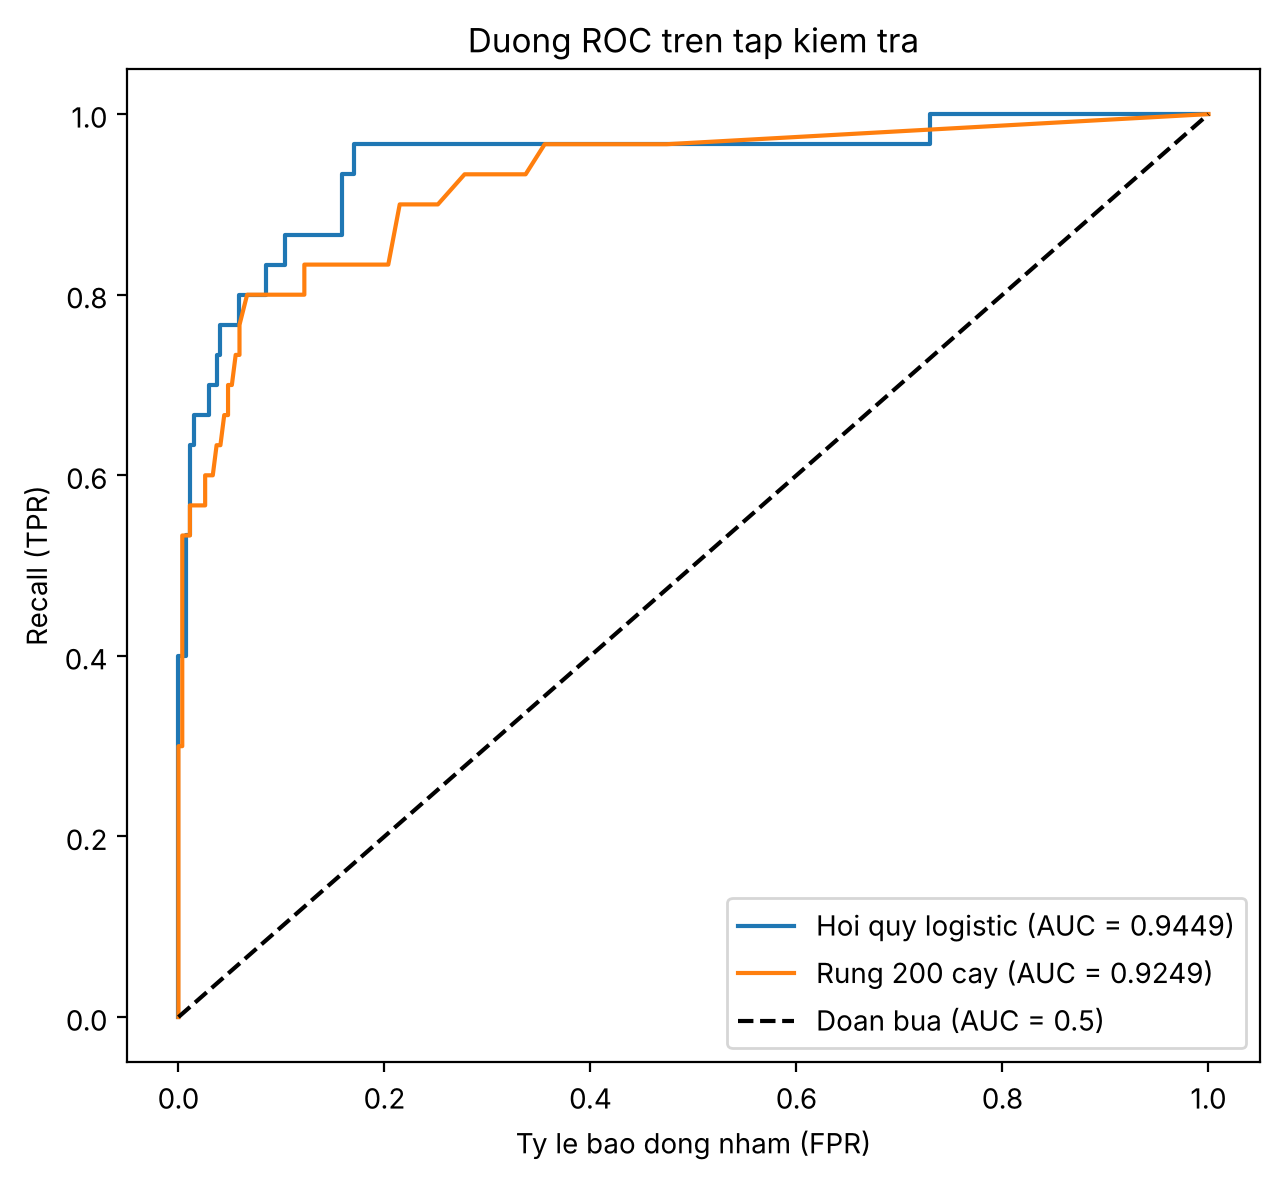

AUC logistic = 0.9449, AUC rung = 0.9249
Phan truc FPR ma logistic cao hon: 59.8%
Phan truc FPR ma rung cao hon    : 25.9%
So lan hai duong doi cho cho nhau: 4

 FPR    TPR logistic   TPR rung
 0.01      0.5333        0.5333
 0.02      0.6667        0.5667
 0.05      0.7667        0.7000
 0.10      0.8333        0.8000
 0.20      0.9667        0.8333
 0.40      0.9667        0.9667


In [12]:
rung = RandomForestClassifier(200, random_state=0).fit(X_tr, y_tr)
xac_suat_rung = rung.predict_proba(X_te)[:, 1]

fpr_lr, tpr_lr, _ = roc_curve(y_te, xac_suat_kt)
fpr_rung, tpr_rung, _ = roc_curve(y_te, xac_suat_rung)
auc_lr = roc_auc_score(y_te, xac_suat_kt)
auc_rung = roc_auc_score(y_te, xac_suat_rung)

plt.figure(figsize=(6.5, 6))
plt.plot(fpr_lr, tpr_lr, label=f"Hoi quy logistic (AUC = {auc_lr:.4f})")
plt.plot(fpr_rung, tpr_rung, label=f"Rung 200 cay (AUC = {auc_rung:.4f})")
plt.plot([0, 1], [0, 1], "k--", label="Doan bua (AUC = 0.5)")
plt.xlabel("Ty le bao dong nham (FPR)")
plt.ylabel("Recall (TPR)")
plt.title("Duong ROC tren tap kiem tra")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig("roc.png", dpi=150)
plt.show()

# So hai duong tren cung mot luoi FPR de biet duong nao cao hon o dau
luoi_fpr = np.linspace(0, 1, 1001)
tpr_lr_noi = np.interp(luoi_fpr, fpr_lr, tpr_lr)
tpr_rung_noi = np.interp(luoi_fpr, fpr_rung, tpr_rung)
chenh = tpr_lr_noi - tpr_rung_noi
print(f"AUC logistic = {auc_lr:.4f}, AUC rung = {auc_rung:.4f}")
print(f"Phan truc FPR ma logistic cao hon: {(chenh > 1e-9).mean():.1%}")
print(f"Phan truc FPR ma rung cao hon    : {(chenh < -1e-9).mean():.1%}")
dau = np.sign(chenh[np.abs(chenh) > 1e-9])
print("So lan hai duong doi cho cho nhau:", int((np.diff(dau) != 0).sum()))
print()
print(" FPR    TPR logistic   TPR rung")
for muc in [0.01, 0.02, 0.05, 0.10, 0.20, 0.40]:
    print(f" {muc:.2f}      {np.interp(muc, fpr_lr, tpr_lr):.4f}        "
          f"{np.interp(muc, fpr_rung, tpr_rung):.4f}")

**Nhận xét:** Đường của hồi quy logistic ôm sát góc trên bên trái hơn, với AUC 0.9449 so với 0.9249 của rừng 200 cây. Ở vùng quan trọng nhất là báo động nhầm thấp, logistic cao hơn rõ: tại FPR 0.02, recall là 0.6667 so với 0.5667; tại FPR 0.05 là 0.7667 so với 0.7000; tại FPR 0.20 là 0.9667 so với 0.8333.

## Bài tập 5: Cân bằng lớp cho mô hình khác

In [13]:
cac_mo_hinh = {
    "Rung, binh thuong": RandomForestClassifier(200, random_state=0),
    "Rung, can bang   ": RandomForestClassifier(200, random_state=0,
                                                class_weight="balanced"),
    "SVC, binh thuong ": make_pipeline(StandardScaler(), SVC(random_state=0)),
    "SVC, can bang    ": make_pipeline(StandardScaler(),
                                       SVC(random_state=0, class_weight="balanced")),
}
print("Mo hinh             so bao   precision   recall     F1")
ket_qua_can_bang = {}
for ten, mo_hinh in cac_mo_hinh.items():
    du_doan = mo_hinh.fit(X_tr, y_tr).predict(X_te)
    ket_qua_can_bang[ten] = (precision_score(y_te, du_doan, zero_division=0),
                             recall_score(y_te, du_doan), f1_score(y_te, du_doan))
    pre, rec, f1 = ket_qua_can_bang[ten]
    print(f" {ten}   {du_doan.sum():4d}     {pre:.4f}     {rec:.4f}   {f1:.4f}")

Mo hinh             so bao   precision   recall     F1


 Rung, binh thuong     22     0.7727     0.5667   0.6538


 Rung, can bang        39     0.5385     0.7000   0.6087
 SVC, binh thuong      17     0.8824     0.5000   0.6383
 SVC, can bang         56     0.4464     0.8333   0.5814


**Nhận xét:** Cân bằng lớp đẩy cả hai mô hình về phía báo nhiều hơn: recall tăng, precision giảm.

**SVC thay đổi nhiều nhất:** recall tăng 0.3333 (từ 0.5000 lên 0.8333, tìm thêm 10 bạn), precision giảm 0.4360 và số bạn bị báo tăng hơn ba lần, từ 17 lên 56. Rừng thay đổi ít hơn: recall tăng 0.1333, precision giảm 0.2342, số bạn bị báo tăng từ 22 lên 39. F1 của cả hai đều giảm nhẹ (rừng 0.6538 xuống 0.6087, SVC 0.6383 xuống 0.5814), vì phần precision mất đi lớn hơn phần recall được thêm.

Cân bằng lớp không làm mô hình "giỏi hơn", nó chỉ đổi điểm đánh đổi giữa precision và recall, giống như hạ ngưỡng. Có nên dùng hay không tuỳ vào việc bỏ sót một bạn bỏ học tốn kém hơn hay báo nhầm một bạn tốn kém hơn. Các con số trên là từ một lần chia dữ liệu với 30 bạn bỏ học trong tập kiểm tra.

## Bài tập 6: MAE và RMSE với một lần đoán hỏng

In [ ]:
gia_nha = doc_csv("gia_nha.csv")
X_gia = gia_nha[["dien_tich"]]
y_gia = gia_nha["gia"]
X_gia_tr, X_gia_te, y_gia_tr, y_gia_te = train_test_split(
    X_gia, y_gia, test_size=0.2, random_state=42
)
duong_thang = LinearRegression().fit(X_gia_tr, y_gia_tr)
gia_du_doan = duong_thang.predict(X_gia_te)


def ba_thuoc_do(y_that, y_doan):
    mae = mean_absolute_error(y_that, y_doan)
    rmse = np.sqrt(mean_squared_error(y_that, y_doan))
    return mae, rmse, r2_score(y_that, y_doan)


# Cong them 5 ty vao du doan cua dung mot can (can dau tien cua tap kiem tra)
gia_du_doan_hong = gia_du_doan.copy()
gia_du_doan_hong[0] += 5.0

truoc = ba_thuoc_do(y_gia_te, gia_du_doan)
sau = ba_thuoc_do(y_gia_te, gia_du_doan_hong)
print(f"Tap kiem tra co {len(y_gia_te)} can")
print("            truoc      sau     thay doi")
for ten, a, b in zip(["MAE ", "RMSE", "R2  "], truoc, sau):
    ghi_chu = f"gap {b / a:.2f} lan" if ten != "R2  " else f"giam {a - b:.4f}"
    print(f" {ten}     {a:7.4f}  {b:7.4f}   {ghi_chu}")
print()

sai_so = np.abs(y_gia_te.to_numpy() - gia_du_doan_hong)
print(f"Sai so cua can bi doan hong: {sai_so[0]:.2f} ty")
print(f"Phan dong gop cua can do vao tong sai so tuyet doi (MAE)   : "
      f"{sai_so[0] / sai_so.sum():.1%}")
print(f"Phan dong gop cua can do vao tong binh phuong sai so (RMSE): "
      f"{sai_so[0] ** 2 / (sai_so ** 2).sum():.1%}")

Tap kiem tra co 12 can
            truoc      sau     thay doi
 MAE       0.2578   0.6745   gap 2.62 lan
 RMSE      0.3730   1.5505   gap 4.16 lan
 R2        0.9622   0.3475   giam 0.6148

Sai so cua can bi doan hong: 5.22 ty
Phan dong gop cua can do vao tong sai so tuyet doi (MAE)   : 64.5%
Phan dong gop cua can do vao tong binh phuong sai so (RMSE): 94.4%


**Nhận xét:** Trước khi làm hỏng, trên 12 căn kiểm tra: MAE = 0.2578 tỷ, RMSE = 0.3730 tỷ, R² = 0.9622. Sau khi cộng 5 tỷ vào dự đoán của đúng một căn: MAE = 0.6745 (gấp 2.62 lần), RMSE = 1.5505 (gấp 4.16 lần), R² = 0.3475 (giảm 0.6148).